# dots.mocr — 3B Multimodal Vision-Language Model Layout Analysis Pipeline

Pipeline phân tích layout tài liệu bằng mô hình thị giác - ngôn ngữ đa phương thức **dots.mocr** (3B tham số, phát triển bởi nhóm nghiên cứu **RedNote HI Lab / Dots Studio**).

### Kiến trúc Vision-Language Model (VLM)
- **Backbone**: Mô hình Transformer thị giác - ngôn ngữ đa phương thức 3B tham số tối ưu hóa (Qwen2-VL backbone), hỗ trợ xử lý độ phân giải cao và hiểu sâu ngữ cảnh tài liệu.
- **End-to-End Layout Parsing**: Mô hình sinh trực tiếp cấu trúc layout tài liệu dạng JSON gồm danh sách bounding box `[x1, y1, x2, y2]` và nhãn phân loại tương ứng thông qua text prompt có cấu trúc.
- **Taxonomy Mapping (1-1)**: dots.mocr hỗ trợ trực tiếp 11 danh mục chuẩn của **DocLayNet** (`Caption`, `Footnote`, `Formula`, `List-item`, `Page-footer`, `Page-header`, `Picture`, `Section-header`, `Table`, `Text`, `Title`) và tự động ánh xạ sang 5 danh mục của **PubLayNet** khi cần.

In [1]:
from pathlib import Path
import subprocess
import sys

# Khởi tạo đường dẫn gốc project
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "methods").is_dir():
    raise FileNotFoundError("Không tìm thấy thư mục gốc repository; hãy mở notebook từ project DO-AN-261.")

METHOD = "dots_mocr"
DATASET = "doclaynet_test"
SPLIT = "test"
IOU_THRESHOLD = 0.5
LIMIT = 150  # gioi han do VLM sinh cham tren GPU 8GB (~110s/anh)
FORCE_INFERENCE = False  # True: chạy lại inference và ghi đè; False: bỏ qua ảnh đã có prediction
FIGURE_LIMIT = 10

PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
FIGURES_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
print(f"Project: {ROOT}")
print(f"Pipeline: {METHOD} | {DATASET}/{SPLIT} | IoU >= {IOU_THRESHOLD}")
print(f"Inference: {'force rerun' if FORCE_INFERENCE else 'skip existing predictions'}")
print(f"Predictions: {PREDICTIONS_DIR}")
print(f"Figures: {FIGURES_DIR}")


Project: D:\DLA\DO-AN-261
Pipeline: dots_mocr | doclaynet_test/test | IoU >= 0.5
Inference: skip existing predictions
Predictions: D:\DLA\DO-AN-261\outputs\predictions\dots_mocr\doclaynet_test
Figures: D:\DLA\DO-AN-261\outputs\reports\dots_mocr_doclaynet_test


## 0. Kiểm tra mã nguồn, môi trường và tự động tải trọng số (Setup & Auto-Download)

Tế bào này kiểm tra sự tồn tại của thư viện phụ thuộc (`transformers`, `qwen-vl-utils`), bộ trọng số chính thức của `dots.mocr` từ Hugging Face Hub (`dots-studio/dots.mocr`), và tập dữ liệu. Nếu chưa có file trọng số, hệ thống sẽ tự động tải về thư mục `methods/dots_mocr/weights/` để người dùng có thể chạy trực tiếp toàn bộ notebook.

In [2]:
import subprocess
import sys
from pathlib import Path

# 1. Kiểm tra thư viện phụ thuộc (qwen-vl-utils, accelerate, pycocotools)
for pkg in ['qwen-vl-utils', 'accelerate', 'pycocotools']:
    try:
        __import__(pkg.replace('-', '_'))
    except ImportError:
        print(f'[Setup] Cài đặt {pkg}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg])
print('[OK] Các thư viện phụ thuộc đã sẵn sàng.')

# 2. Kiểm tra và tự động tải trọng số pre-trained nếu chưa có
weights_dir = ROOT / "methods" / "dots_mocr" / "weights"
weights_dir.mkdir(parents=True, exist_ok=True)
has_weights = (weights_dir / "config.json").exists() and any(weights_dir.glob("*.safetensors"))

if not has_weights:
    print("[Setup] Chưa có file trọng số dots.mocr cục bộ. Đang tự động tải về từ Hugging Face (dots-studio/dots.mocr)...")
    from huggingface_hub import snapshot_download
    snapshot_download(repo_id="dots-studio/dots.mocr", local_dir=str(weights_dir), ignore_patterns=["*.msgpack", "*.h5", "*.ot"])
    print("[OK] Tải trọng số dots.mocr thành công!")
else:
    print(f"[OK] Trọng số dots.mocr đã sẵn sàng tại: {weights_dir}")

# 3. Kiểm tra tập dữ liệu DocLayNet
images_dir = ROOT / "datasets" / DATASET / "processed" / "images"
if not images_dir.is_dir() or not any(images_dir.glob("*.png")):
    print(f"[Cảnh báo] Chưa tìm thấy ảnh tại: {images_dir}. Hãy đảm bảo đã chuẩn bị dataset trước khi chạy inference.")
else:
    num_images = len(list(images_dir.glob("*.png")))
    print(f"[OK] Tập dữ liệu {DATASET} sẵn sàng ({num_images} ảnh).")


[OK] Các thư viện phụ thuộc đã sẵn sàng.
[OK] Trọng số dots.mocr đã sẵn sàng tại: D:\DLA\DO-AN-261\methods\dots_mocr\weights
[OK] Tập dữ liệu doclaynet_test sẵn sàng (4999 ảnh).


## 1. Prediction

Chạy layout detection bằng script `methods/dots_mocr/src/run_inference.py`. Script nạp model VLM 3B, gửi prompt bóc tách layout và sinh kết quả dự đoán ra `outputs/predictions/dots_mocr/<dataset>/`.

In [3]:
inference_script = ROOT / "methods" / METHOD / "src" / "run_inference.py"
cmd = [
    sys.executable,
    str(inference_script),
    "--dataset", DATASET,
    "--limit", str(LIMIT),
]
if not FORCE_INFERENCE:
    cmd.append("--skip-existing")
else:
    cmd.append("--force")

print(f"Running: {' '.join(cmd)}")
res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), encoding="utf-8", errors="replace")
print(res.stdout)
if res.stderr:
    print("Errors / Warnings:", res.stderr[-500:])


Running: D:\DLA\docling_env\Scripts\python.exe D:\DLA\DO-AN-261\methods\dots_mocr\src\run_inference.py --dataset doclaynet_test --limit 150 --skip-existing


[dots_mocr] 150 image(s) to predict from D:\DLA\DO-AN-261\datasets\doclaynet_test\processed\images (device: cuda) (existing predictions skipped)
[dots_mocr] Sử dụng trọng số có sẵn tại: D:\DLA\DO-AN-261\methods\dots_mocr\weights
[dots_mocr] Khởi tạo mô hình từ: D:\DLA\DO-AN-261\methods\dots_mocr\weights (device=cuda)
[dots_mocr] Model loaded successfully in 12.49s
  [1/150] 1.png: 9 boxes (9.03s)
  [2/150] 2.png: 10 boxes (8.29s)
  [3/150] 3.png: 16 boxes (12.47s)
  [4/150] 4.png: 14 boxes (11.40s)
  [5/150] 5.png: 17 boxes (13.45s)
  [6/150] 6.png: 12 boxes (11.43s)
  [7/150] 7.png: 4 boxes (4.39s)
  [8/150] 8.png: 9 boxes (8.19s)
  [9/150] 9.png: 20 boxes (18.50s)
  [10/150] 10.png: 13 boxes (14.62s)
  [11/150] 11.png: 19 boxes (20.88s)
  [12/150] 13.png: 14 boxes (14.68s)
  [13/150] 14.png: 3 boxes (4.08s)
  [14/150] 15.png: 11 boxes (13.09s)
  [15/150] 16.png: 11 boxes (12.25s)
  [16/150] 17.png: 13 boxes (15.31s)
  [17/150] 18.png: 26 boxes (27.27s)
  [18/150] 19.png: 5 boxes (5.8

## 2. Metrics and Evaluation Chart

Đánh giá các dự đoán layout theo chuẩn COCO và benchmark DocLayNet:
- **Strict**: Yêu cầu khớp cả tọa độ (IoU >= threshold) và đúng nhãn layout.
- **Loose**: Chỉ đánh giá khả năng định vị (localization), bỏ qua nhãn.
- **COCO mAP**: Tính toán mAP@[0.5:0.95] và mAP@0.5.
- **Biểu đồ**: Trực quan hóa Precision, Recall, F1 theo từng class và so sánh Strict vs Loose.

Running evaluation:


Evaluation: dots_mocr on doclaynet_test/test | 150 images | GT=1,951 boxes | Predictions=1,982 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.086  Recall=0.087  F1=0.086  TP=170 FP=1812 FN=1781  mean IoU=0.610
Macro (mean across 10 ground-truth classes): Precision=0.073  Recall=0.077  F1=0.075
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                   979     995     83    912    896    0.083    0.085    0.084
Section-header         292     268      4    264    288    0.015    0.014    0.014
Picture                184     199     28    171    156    0.141    0.152    0.146
Page-footer            133     131      0    131    133    0.000    0.000    0.000
Table                  111     115     46     69     65    0.400    0.414    0.407
List-item               93      84      4     80     89    0.048    0.043    0.045
Page-header             80     106      5    101     75    0.047    0.062    0.054
Caption      

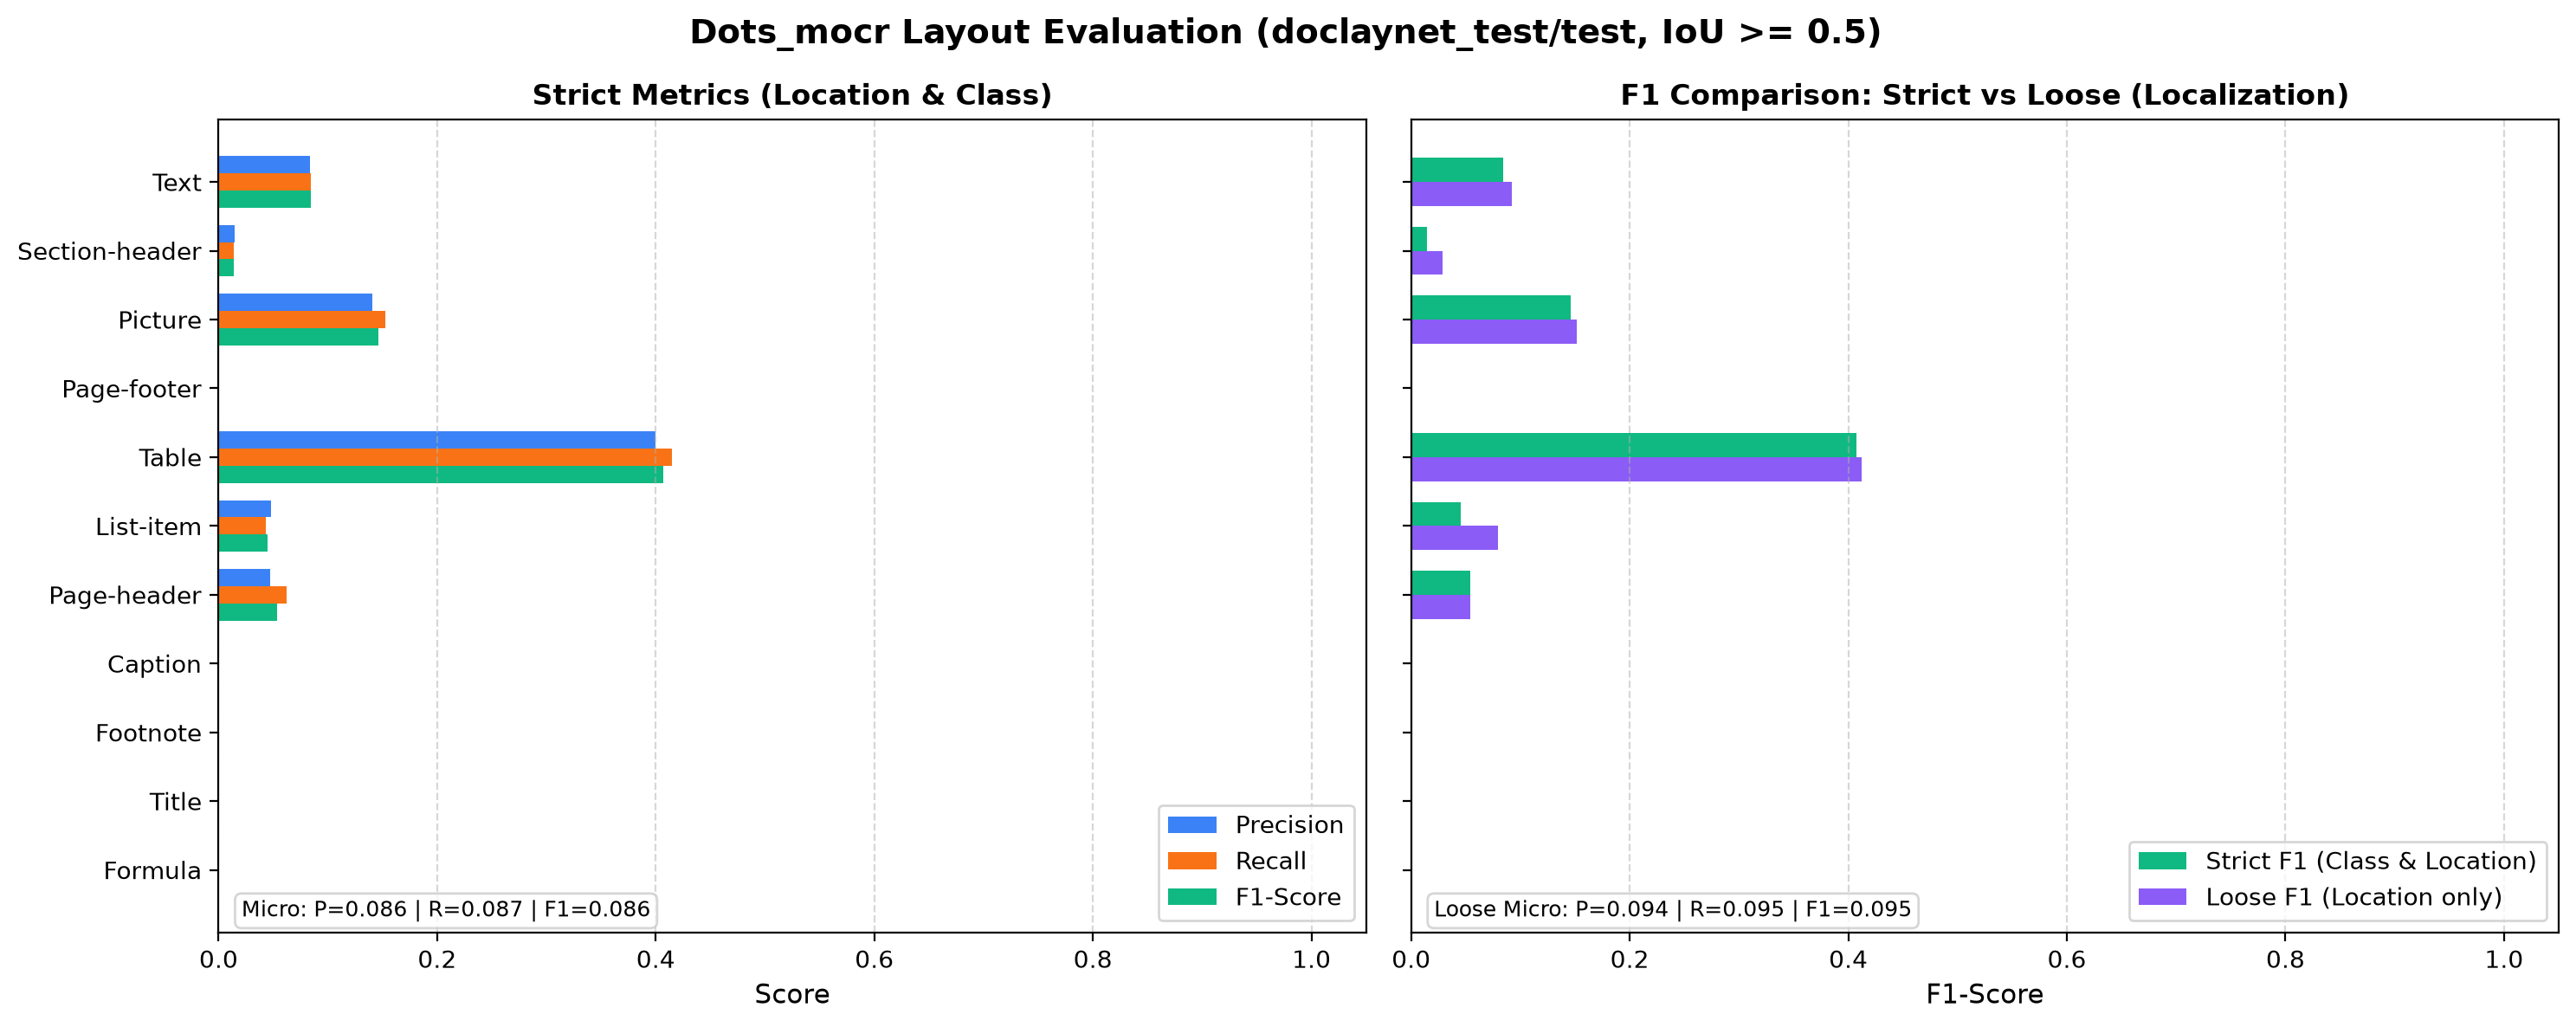

In [4]:
eval_script = ROOT / "scripts" / "evaluate_predictions.py"
chart_path = FIGURES_DIR / "metrics_chart.png"
chart_path.parent.mkdir(parents=True, exist_ok=True)

cmd = [
    sys.executable,
    str(eval_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", str(IOU_THRESHOLD),
    "--allow-incomplete",
    "--loose",
    "--plot", str(chart_path),
]

print("Running evaluation:")
res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), encoding="utf-8", errors="replace")
print(res.stdout)
if res.stderr:
    print("Errors / Warnings:", res.stderr[-500:])

if chart_path.exists():
    from IPython.display import Image, display
    print(f"\nEvaluation Chart ({chart_path}):")
    display(Image(filename=str(chart_path)))


## 3. Ground Truth vs. Prediction Examples

Vẽ bounding box Ground Truth (bên trái) đối chiếu với dự đoán của dots.mocr (bên phải) cạnh nhau trên cùng một ảnh để trực quan hóa chất lượng nhận diện layout.

Running: D:\DLA\docling_env\Scripts\python.exe D:\DLA\DO-AN-261\visualization\scripts\visualize_predictions.py --method dots_mocr --dataset doclaynet_test --split test --limit 10 --output-dir D:\DLA\DO-AN-261\outputs\reports\dots_mocr_doclaynet_test


[viz] Ve 10 anh (dots_mocr vs ground truth) tu D:\DLA\DO-AN-261\visualization\scripts\..\..\outputs\predictions\dots_mocr\doclaynet_test
  [ok] 1.png
  [ok] 2.png
  [ok] 3.png
  [ok] 4.png
  [ok] 5.png
  [ok] 6.png
  [ok] 7.png
  [ok] 8.png
  [ok] 9.png
  [ok] 10.png
[viz] Xong. Anh luu tai D:\DLA\DO-AN-261\outputs\reports\dots_mocr_doclaynet_test


Hiển thị 4 ảnh mẫu (Ground Truth vs dots_mocr):
Ảnh: 1.png


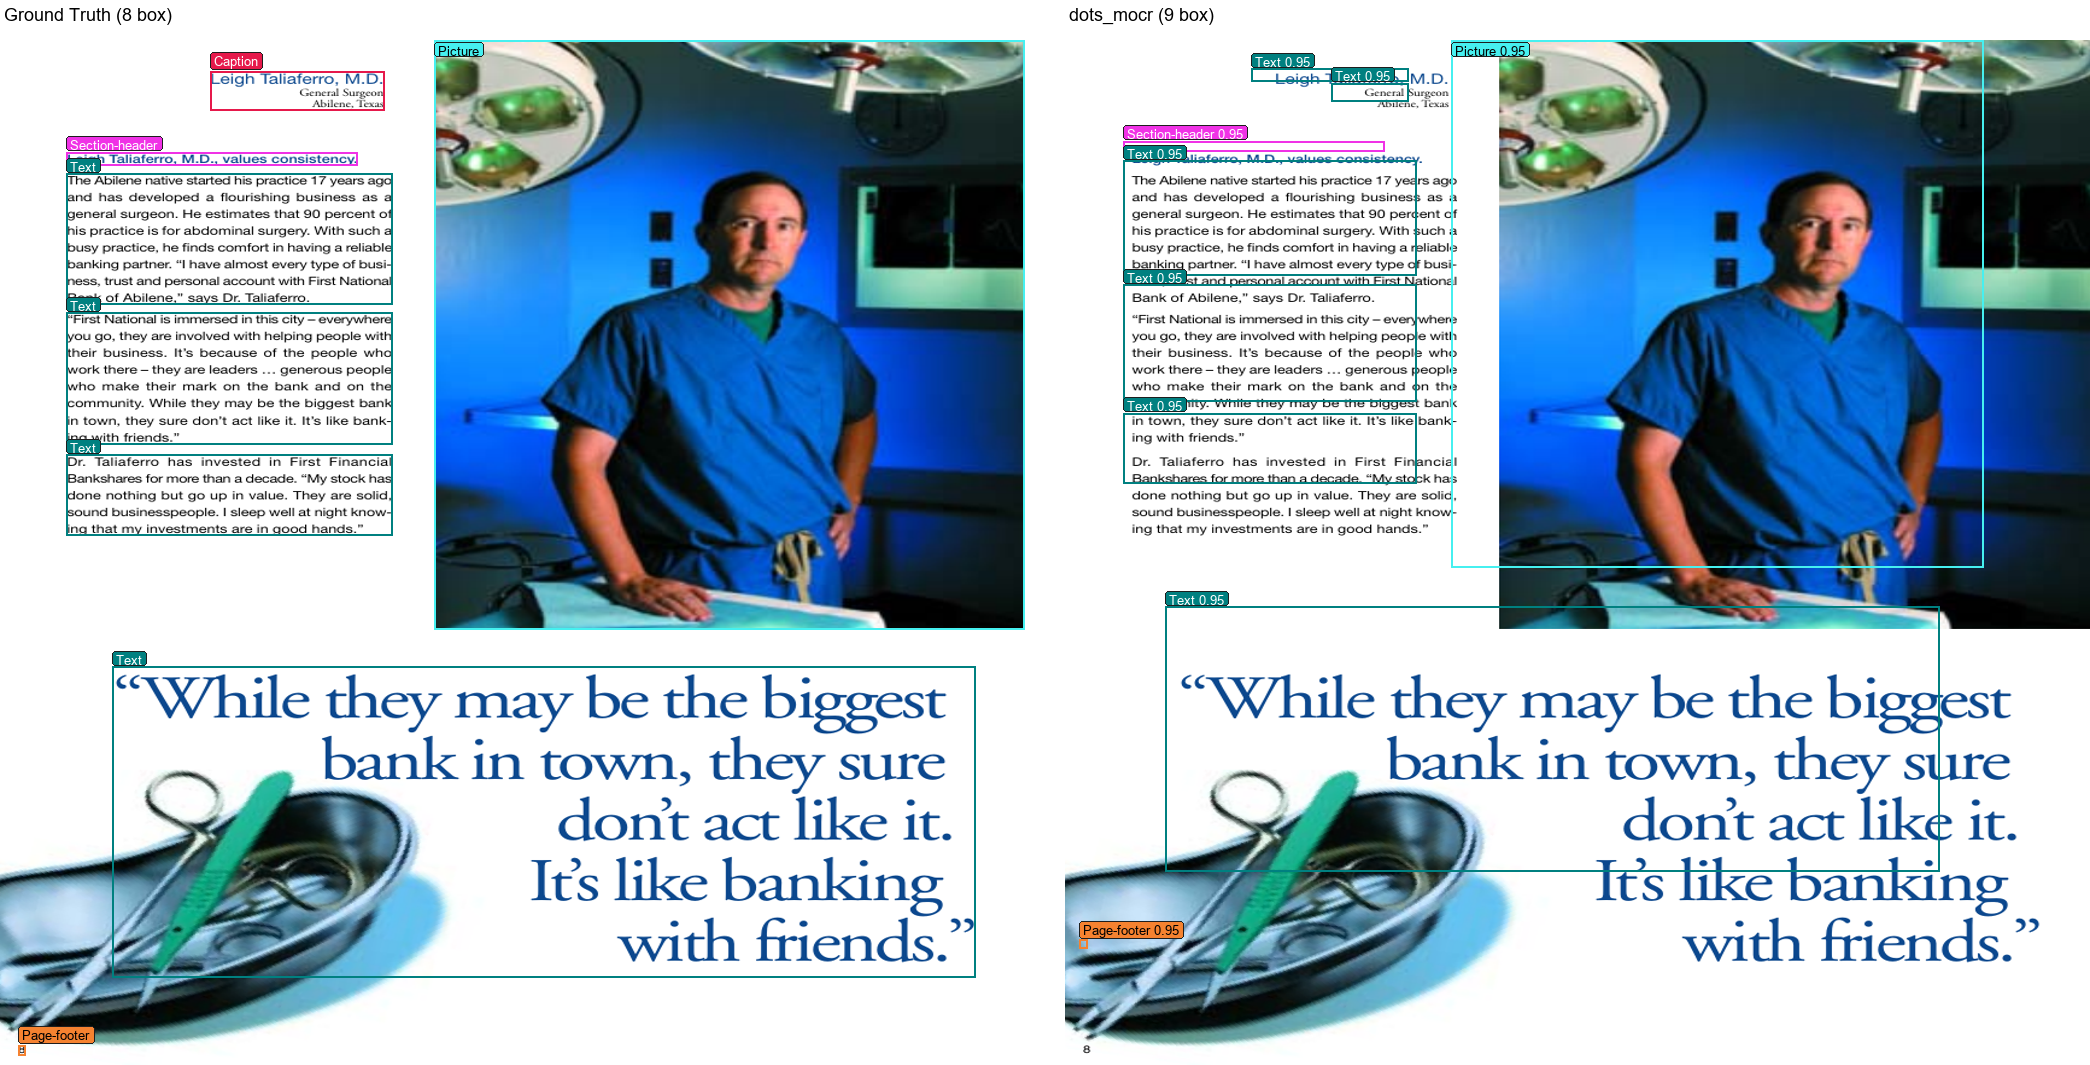

Ảnh: 10.png


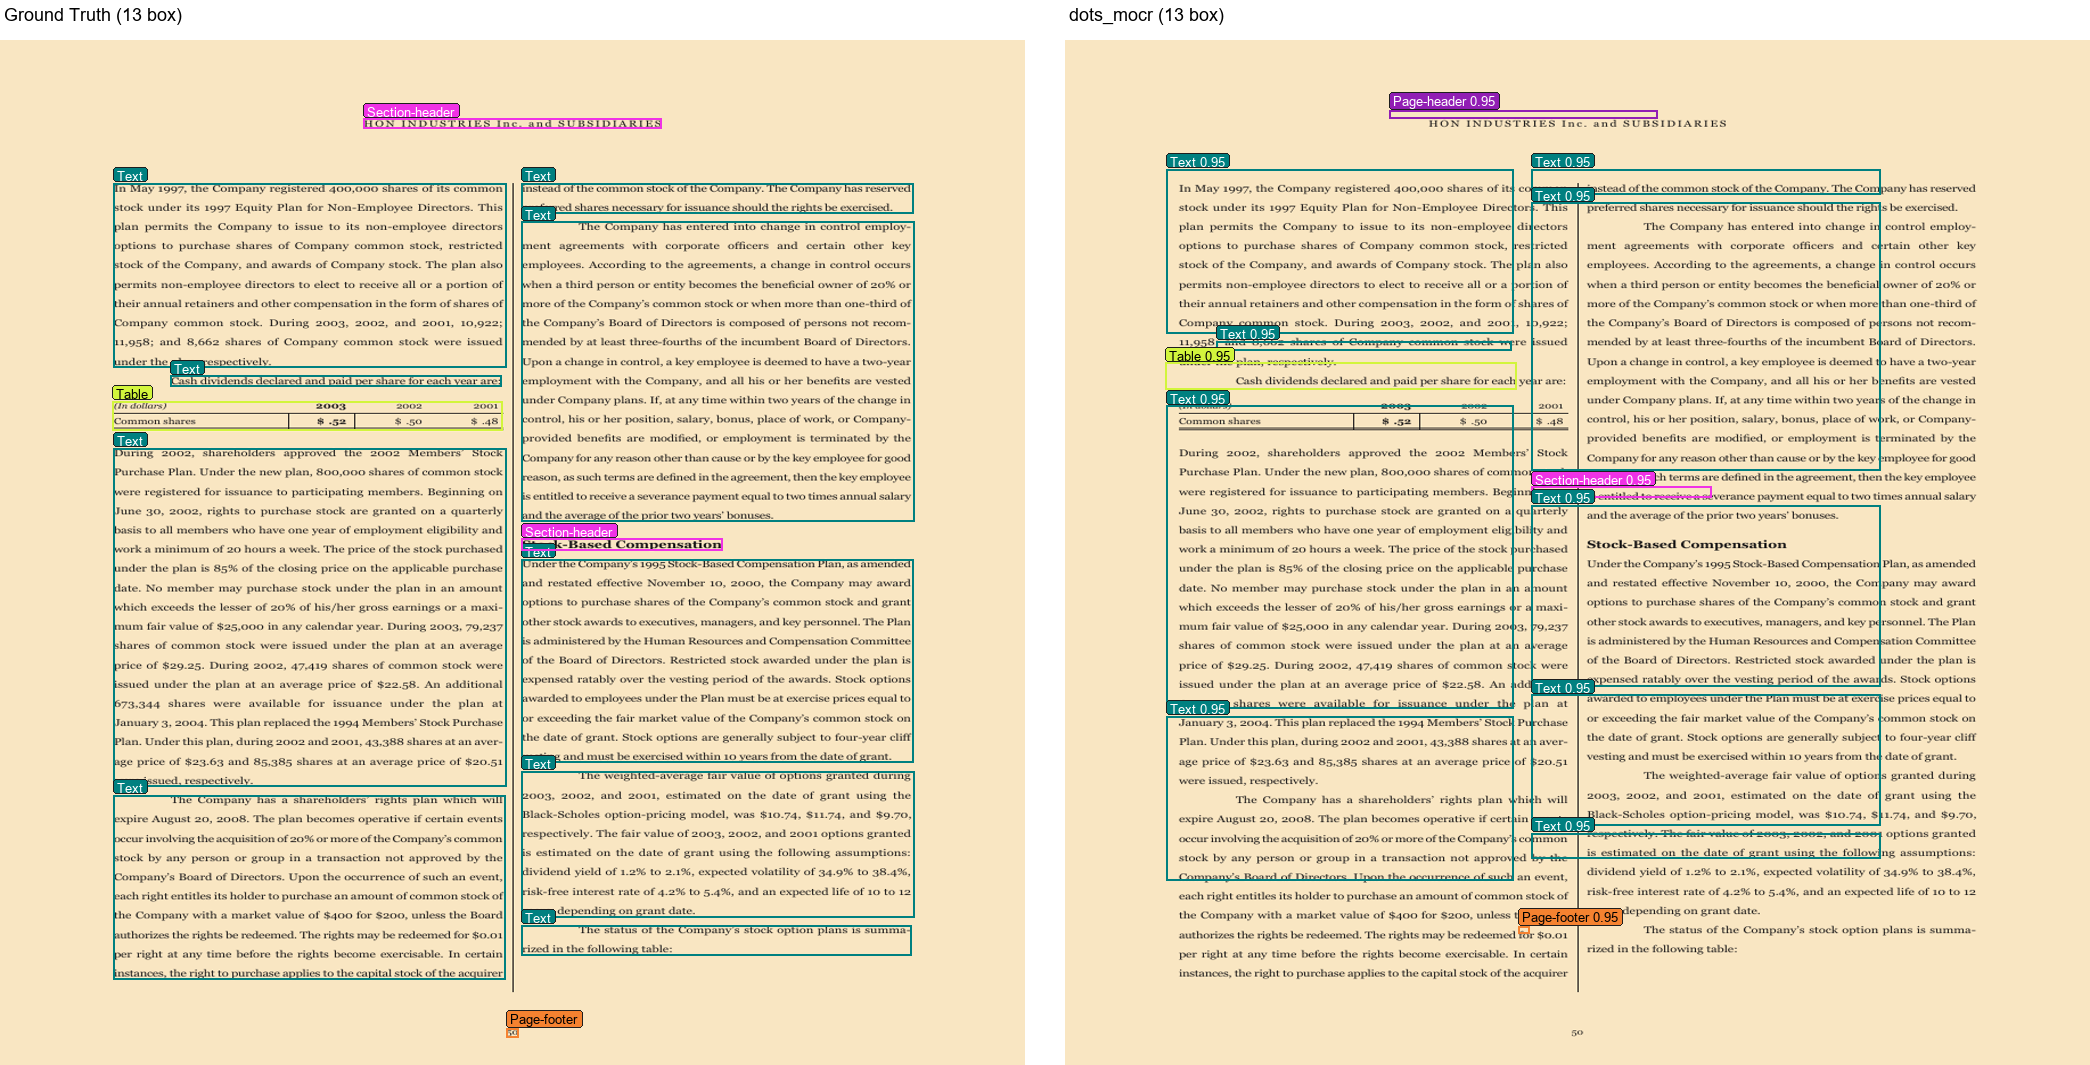

Ảnh: 2.png


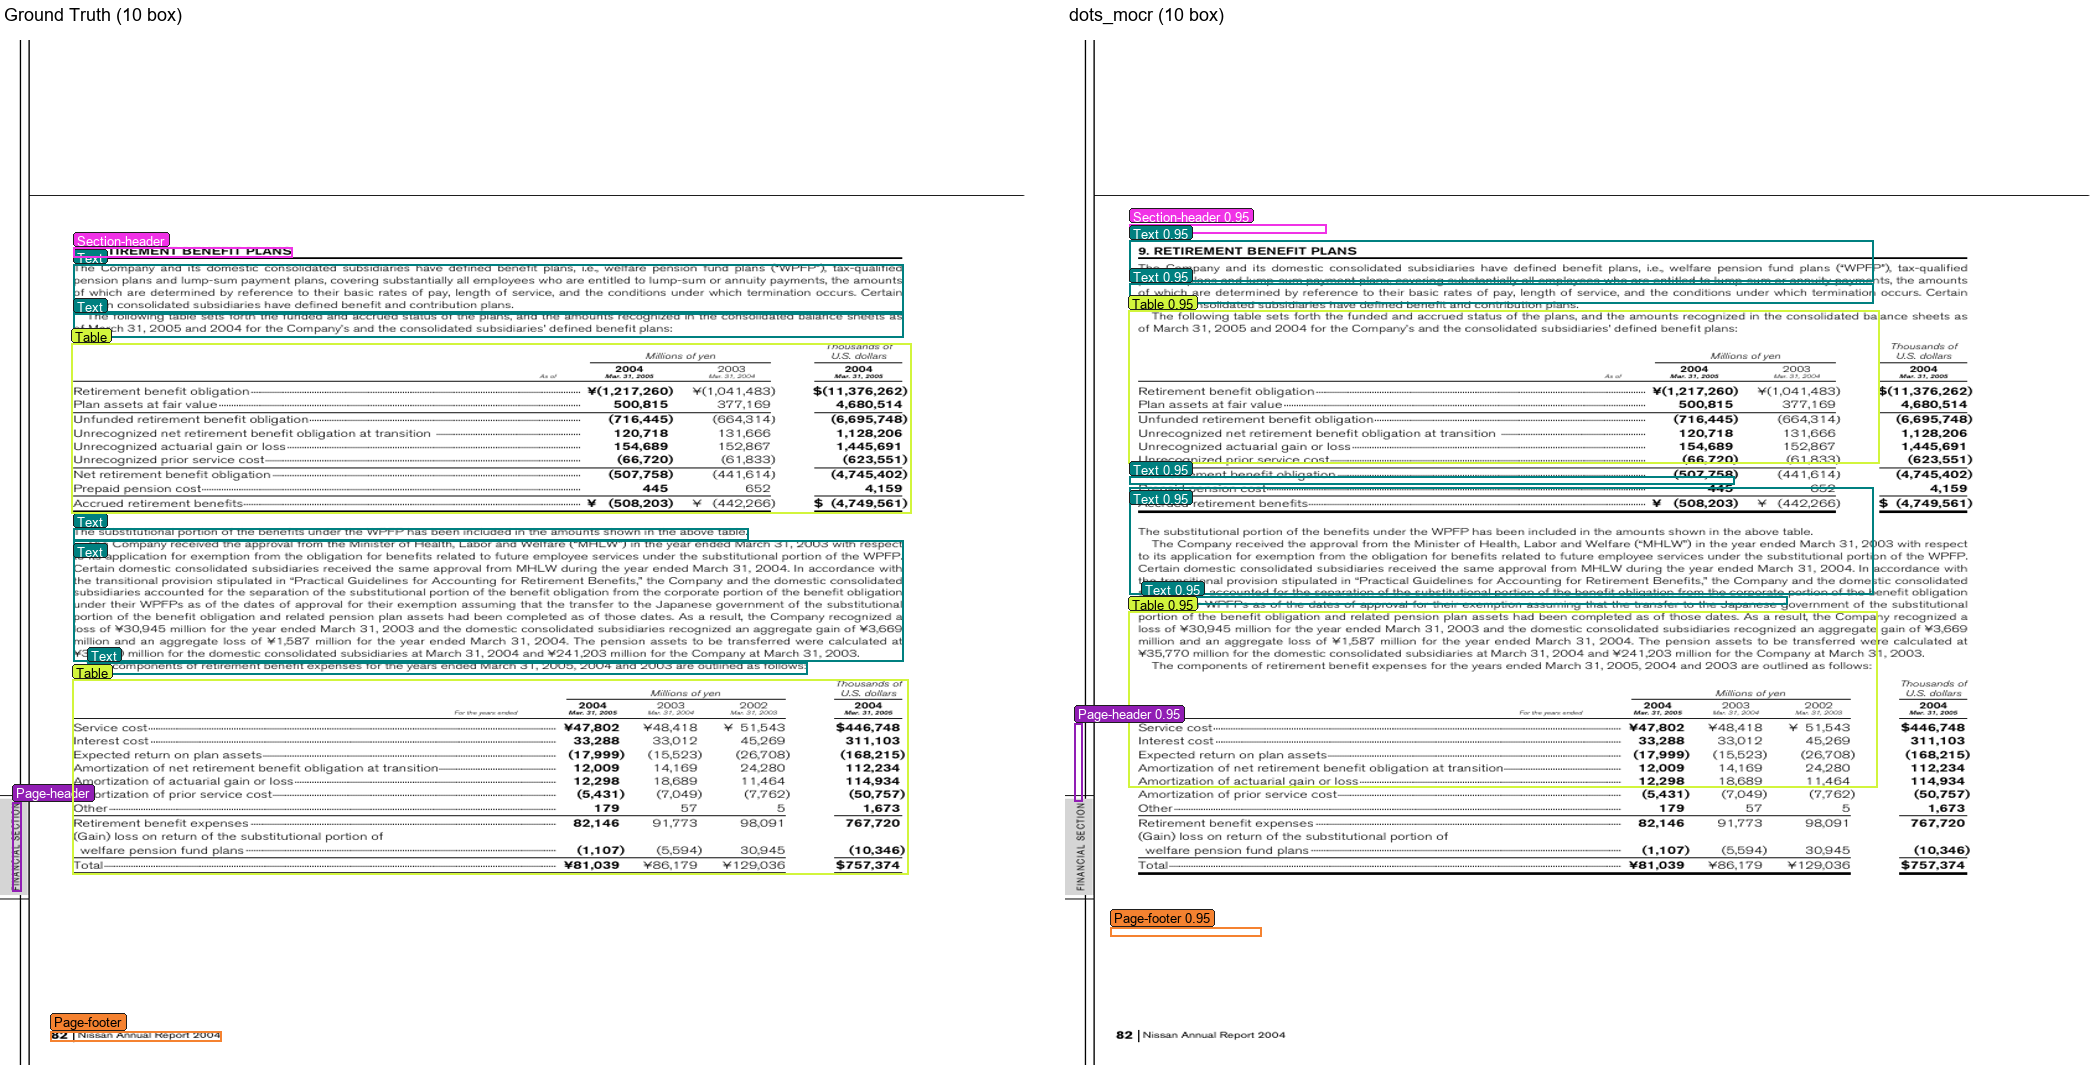

Ảnh: 3.png


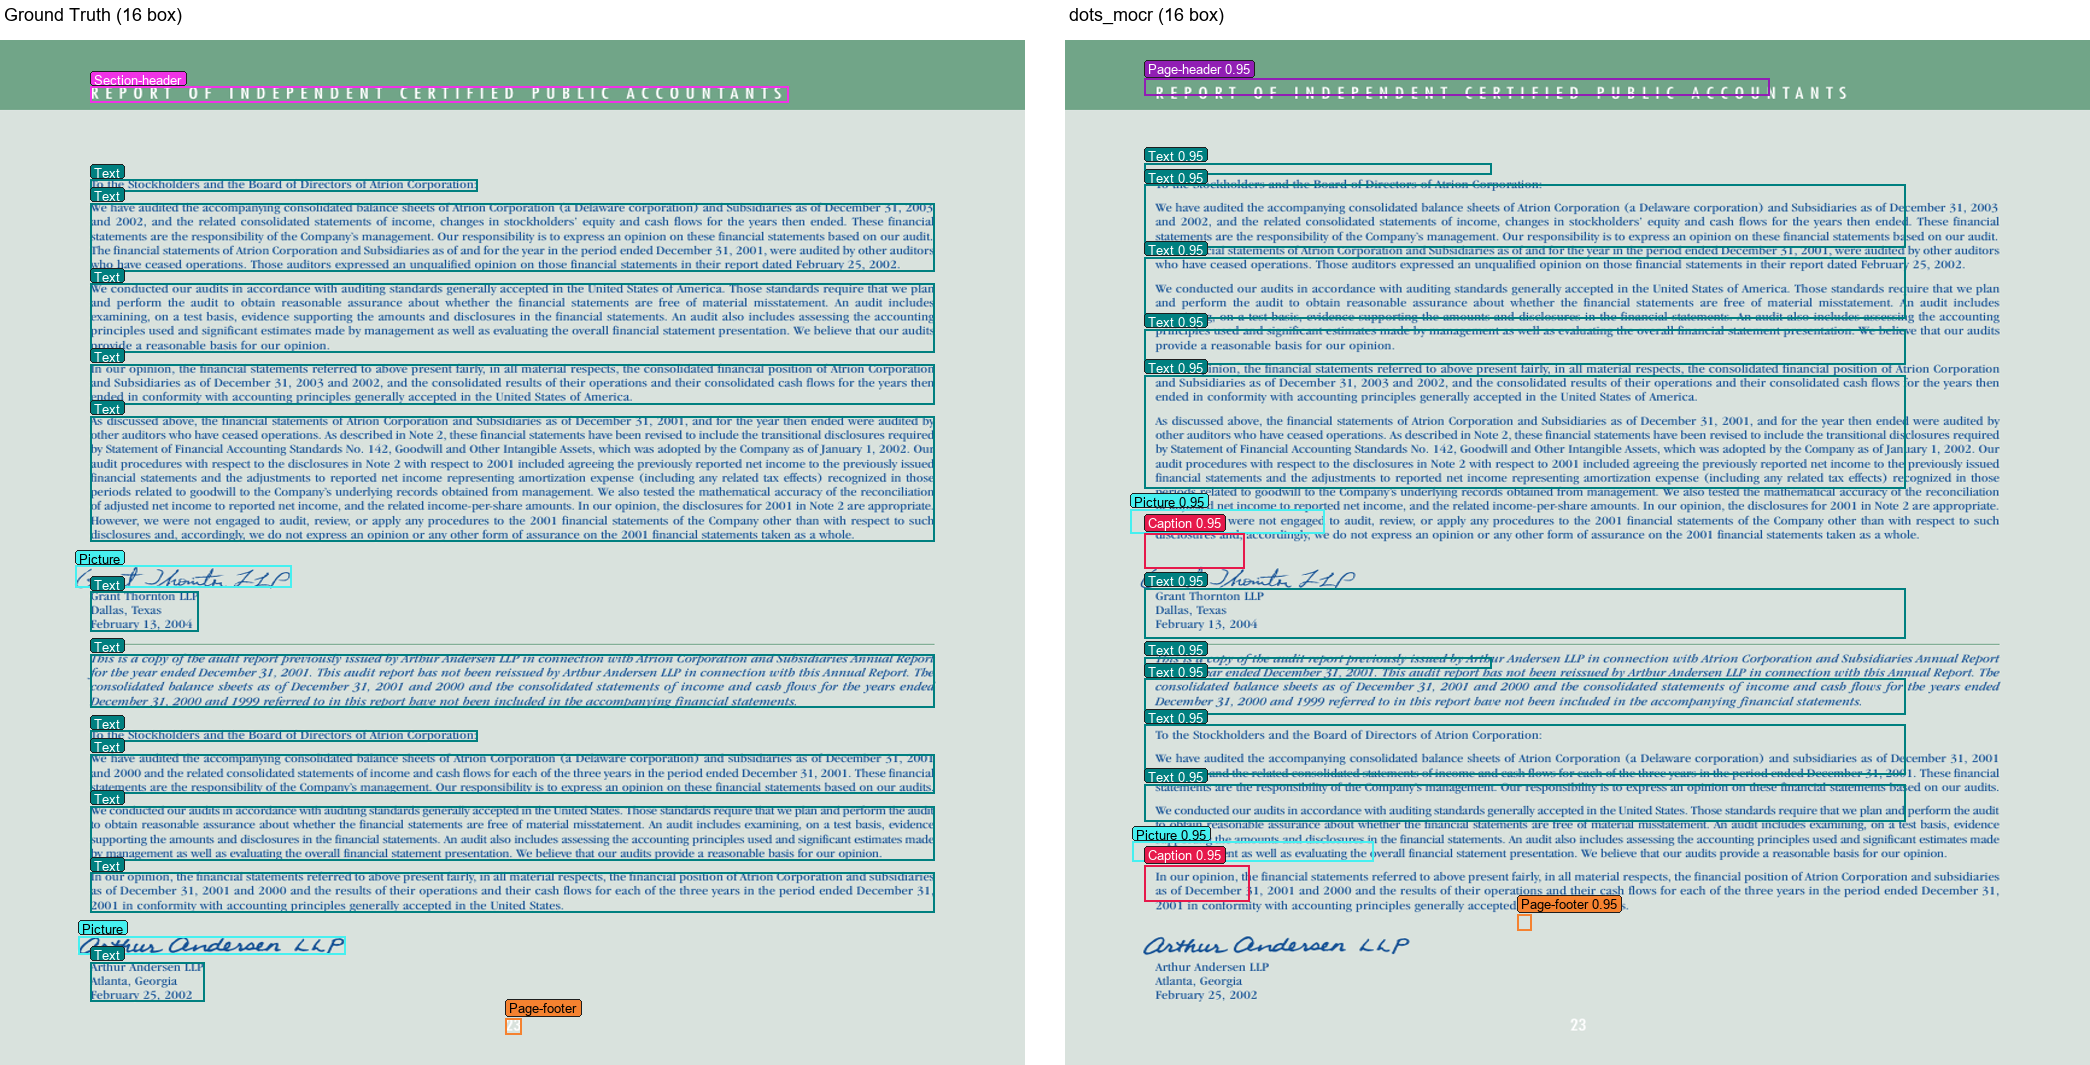

In [5]:
viz_script = ROOT / "visualization" / "scripts" / "visualize_predictions.py"
cmd = [
    sys.executable,
    str(viz_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", str(FIGURE_LIMIT),
    "--output-dir", str(FIGURES_DIR),
]

print(f"Running: {' '.join(cmd)}")
res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), encoding="utf-8", errors="replace")
print(res.stdout)
if res.stderr:
    print("Errors / Warnings:", res.stderr[-500:])

import glob
from IPython.display import Image, display

fig_files = sorted(FIGURES_DIR.glob("*.png"))
sample_files = [f for f in fig_files if f.name != "metrics_chart.png"][:4]
print(f"\nHiển thị {len(sample_files)} ảnh mẫu (Ground Truth vs {METHOD}):")
for f in sample_files:
    print(f"Ảnh: {f.name}")
    display(Image(filename=str(f)))
